<div style="padding:27px 30px;background:#142b3b;color:#f5f8fa;border-radius:12px"><p style="color:#8fdacf;letter-spacing:2px">SQUARES IN SQUARES</p><h1 style="color:#f5f8fa">CUDA Packing Search</h1><p style="font-size:19px;color:#f5f8fa">Reopen contacts · Move whole rows · Recompose improved blocks</p></div>

**Certified local score: 22.383540245659. Lower is better.** Previous scored V12: **22.385710129409**.

Better blocks create new collective motions. This update combines a separately credited public witness refresh with **coherent CUDA C++ restarts**, bounded contact-graph changes, free-angle LP refinement and renewed fault composition. The stage table below measures each accepted increment; a public merge is never counted as a new search discovery.

Default **Run All** restores the frozen numerical result on CPU and freshly validates the actual CSV and a pandas float64 round trip. Optional additional CUDA search is disabled by default. All unit squares retain edge length one.

## Professional edition — execution guide

**Research reproducibility:** Original numerical methods, archived source checks, metric checks and admission logic remain unchanged. The additional sections provide environment diagnostics, preflight checks, experiment reporting and quality analytics.

**Run order:** Execute the setup cell, then preflight. Provide the original `contact_manifest.json` and associated files under `inputs/` (or Kaggle input dataset). Run the original notebook cells in order. The final analytics section is optional. `RECOMPUTE_SEARCH=False` replays the archived result without requiring a GPU; enabling search requires CUDA, CuPy and a compatible NVIDIA GPU.

**Important:** A notebook and source archive alone do not include the original input dataset. Reported historical scores are not independently reproduced until those files are provided and validation runs successfully.

In [ ]:
# Professional preflight: non-mutating environment and input diagnostics
import os, platform, importlib.util, datetime
from pathlib import Path
from IPython.display import display
import pandas as pd
required_files = ['contact_manifest.json','contact_summary.json','contact_gpu_report.json',
                  'contact_v12.csv','contact_public_baseline.csv','contact_submission.csv']
input_dir = next(iter(Path('/kaggle/input').rglob('contact_manifest.json')), Path('inputs/contact_manifest.json')).parent
checks = [{'check':'Python >= 3.10','ok':__import__('sys').version_info >= (3,10), 'detail':platform.python_version()},
          {'check':'Input directory','ok':input_dir.is_dir(),'detail':str(input_dir)}]
checks += [{'check':name,'ok':(input_dir/name).is_file(),'detail':str(input_dir/name)} for name in required_files]
checks += [{'check':'CUDA executable (optional)','ok':__import__('shutil').which('nvidia-smi') is not None,'detail':'Required only for GPU search'},
           {'check':'CuPy installed (optional)','ok':importlib.util.find_spec('cupy') is not None,'detail':'Required only for GPU search'}]
preflight_report = pd.DataFrame(checks)
display(preflight_report)
print('UTC:',datetime.datetime.now(datetime.timezone.utc).isoformat())
print('Replay input ready:',bool(preflight_report.iloc[1:8]['ok'].all()))

In [1]:
from pathlib import Path
import json,csv,hashlib,math,sys,subprocess,shutil
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,HTML,FileLink
RECOMPUTE_SEARCH=False
SEARCH_SECONDS=300
SEARCH_BATCH=128
paths=list(Path('/kaggle/input').rglob('contact_manifest.json')) if Path('/kaggle/input').exists() else []
DATA=paths[0].parent if paths else Path('inputs')
manifest=json.loads((DATA/'contact_manifest.json').read_text())
for name,digest in manifest.items():assert hashlib.sha256((DATA/name).read_bytes()).hexdigest()==digest,name
summary=json.loads((DATA/'contact_summary.json').read_text())
gpu_report=json.loads((DATA/'contact_gpu_report.json').read_text())
plt.rcParams.update({'figure.dpi':130,'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':'#263b4b','text.color':'#263b4b','axes.titleweight':'bold'})
def load(path):
    frame=pd.read_csv(path,float_precision='round_trip')
    return {int(n):g.sort_values('square_id')[['x','y','angle']].to_numpy(float) for n,g in frame.groupby('n')}
def side(p):
    h=(abs(np.cos(p[:,2]))+abs(np.sin(p[:,2])))/2
    return float(((p[:,:2]+h[:,None]).max(0)-(p[:,:2]-h[:,None]).min(0)).max())
before=load(DATA/'contact_v12.csv');public=load(DATA/'contact_public_baseline.csv');after=load(DATA/'contact_submission.csv')

## 1. What changed, and whose improvement is it?

[Kirill Tymchishin V5](https://www.kaggle.com/code/kirilltym/22-3856-cpu-cuda-mps-eda-seam-lp?scriptVersionId=361279753) starts from our V12 and supplies eight further improvements. [Janus's D4 / GPU L-BFGS notebook](https://www.kaggle.com/code/jiwasawa/squares-in-squares-d4-seam-dp-dual-gpu-lbfgs) has a weaker total score but contributes useful individual witnesses. Each imported replacement is independently rechecked. Their combined bank is the baseline for measuring the additional search.

Later rows are **sequential accepted increments**, with overlap removed by per-puzzle selection. They are a trace of this bounded experiment, not a controlled comparison of optimizers.

stage,score,gain,accepted
Scored V12,22.385710129409,0.000000000000,0
Kirill V5 public delta,22.385581714955,0.000128414455,8
Janus public witnesses,22.385194261287,0.000387453667,25
Bounded contact graph scan,22.385193981874,0.000000279413,30
Coherent CUDA restarts,22.383796299440,0.001397682434,46
LP after CUDA restarts,22.383714075350,0.000082224090,24
CUDA donor recomposition,22.383540245659,0.000173829690,13


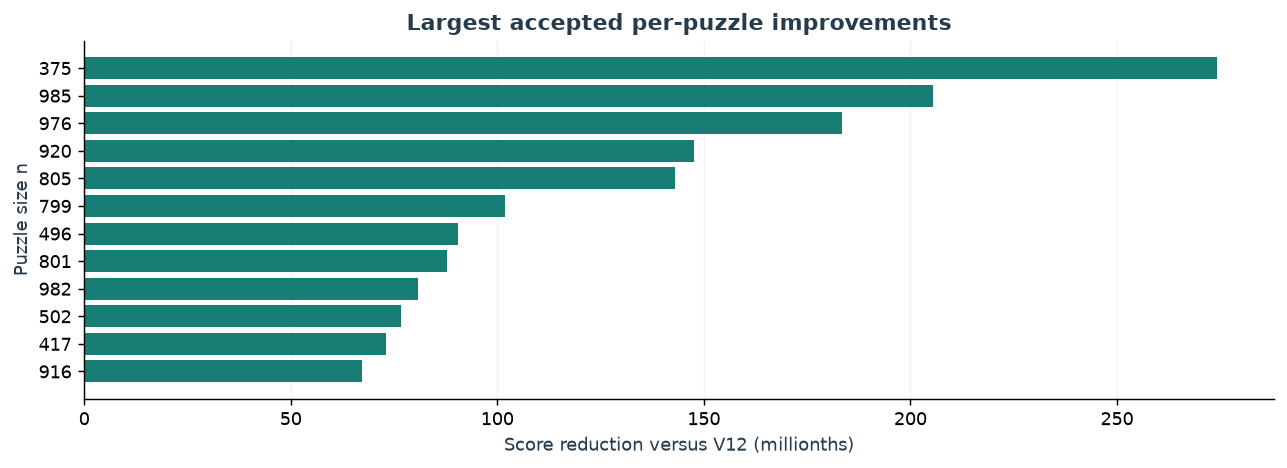

n,V12 side,Final side,Score reduction
375,19.875337302105,19.870025708545,0.000274289512
985,31.866113306070,31.859666573586,0.000205409977
976,31.755460860880,31.749729222977,0.000183465259
920,30.826240552756,30.821764071964,0.000147585201
805,28.864720777585,28.860663763731,0.000142990950
799,28.791832019363,28.788953347223,0.000101840100
496,22.797969388545,22.795954570327,0.000090468009
801,28.816059914395,28.813572716650,0.000087880811
982,31.832545071490,31.830012609148,0.000080814121
502,22.904970583793,22.903251376856,0.000076731961


In [2]:
stages=pd.DataFrame(summary['stages'])
stages['stage']=stages['stage'].replace({'janus_refresh':'Janus public witnesses','graph_switch1':'Bounded contact graph scan','contact_restart1':'Coherent CUDA restarts','graph_after_gpu1':'LP after CUDA restarts','contact_profile1':'CUDA donor recomposition'})
display(HTML(stages[['stage','score','gain','accepted']].to_html(index=False,float_format=lambda x:f'{x:.12f}')))
changes=pd.DataFrame([{'n':n,'V12 side':side(p),'Final side':side(after[n]),'Score reduction':(side(p)-side(after[n]))/math.sqrt(n)} for n,p in before.items() if side(after[n])<side(p)-1e-8]).sort_values('Score reduction',ascending=False)
fig,ax=plt.subplots(figsize=(10,3.7));top=changes.head(12).iloc[::-1]
ax.barh(top.n.astype(str),top['Score reduction']*1e6,color='#187e75')
ax.set(xlabel='Score reduction versus V12 (millionths)',ylabel='Puzzle size n',title='Largest accepted per-puzzle improvements');ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig('contact_gains.png',dpi=165,bbox_inches='tight');plt.show()
display(HTML(changes.head(12).to_html(index=False,float_format=lambda x:f'{x:.12f}')))

## 2. Cross a contact kink with a coordinated move

A local solution can resist individual square motion while allowing a collective row or block motion. A separating-axis LP freezes one separating direction per neighbouring pair; choosing another direction can permit a different motion. [Squarecraft II](https://www.kaggle.com/code/avazaku/squarecraft-ii-unjam-the-grid-22-408597-lb) explicitly searches binary contact choices, including near-valid alternatives that become valid after joint displacement. Kirill alternates separation-graph reclosure and free-angle contact LPs.

The CUDA stage explores these contacts continuously with 128 independent starts per target. Five structured perturbations accompany a mild independent-noise control:

* counter-slide two halves tangentially across a seam;
* rigidly twist one half around its own centroid;
* slide several lattice rows independently;
* rotate the tilted core coherently while retaining its internal geometry initially;
* apply opposite angle changes across a seam.

Each start contracts toward a different target side. A smoothed SAT pressure stage is followed by exact-SAT L-BFGS, both in CUDA C++ with spatial hashing. Overlapping iterates are allowed during exploration. Full independent SAT admission and the official metric decide whether a result enters the bank. The CPU graph pass is bounded and its contribution is measured separately; it is not claimed to be faster than GPU search.

In [3]:
labels={0:'Independent noise',1:'Tangential seam shift',2:'Rigid half twist',3:'Row registry shift',4:'Tilted-core rotation',5:'Opposite angle field'}
events=pd.DataFrame(gpu_report['records'])
print(f"First CUDA restart pass: {gpu_report['attempts']:,} starts; {gpu_report['seconds']:.2f} wall seconds; {gpu_report['cuda_seconds']:.2f} CUDA seconds.")
print('CUDA analytic-gradient check:',gpu_report['checks'])
if len(events):
    grouped=events.groupby('mode').agg(accepted_steps=('n','size'),score_reduction=('gain','sum')).reset_index()
    grouped['initial_perturbation']=grouped['mode'].map(labels)
    display(HTML(grouped[['initial_perturbation','accepted_steps','score_reduction']].to_html(index=False,float_format=lambda x:f'{x:.12f}')))
print('These are winning starts within a mixed search, not equal-budget causal comparisons. Later certification can remove overlapping gains.')

First CUDA restart pass: 34,688 starts; 481.31 wall seconds; 446.06 CUDA seconds.
CUDA analytic-gradient check: {'max_gradient_error': 4.691527027977926e-10, 'square_endpoint_matches': True}


initial_perturbation,accepted_steps,score_reduction
Independent noise,11,0.000084687968
Tangential seam shift,8,0.000250276377
Rigid half twist,8,0.000405783218
Row registry shift,8,0.000037405378
Tilted-core rotation,10,0.000553920046
Opposite angle field,6,0.000070921083


These are winning starts within a mixed search, not equal-budget causal comparisons. Later certification can remove overlapping gains.


## 3. Geometry before and after

Each pair uses identical axis limits. Rotated squares are teal; near-upright squares are blue-grey. The view shows the full unit-square geometry, without magnifying displacements. Small side reductions may be difficult to see at full scale; exact side lengths accompany the plots.

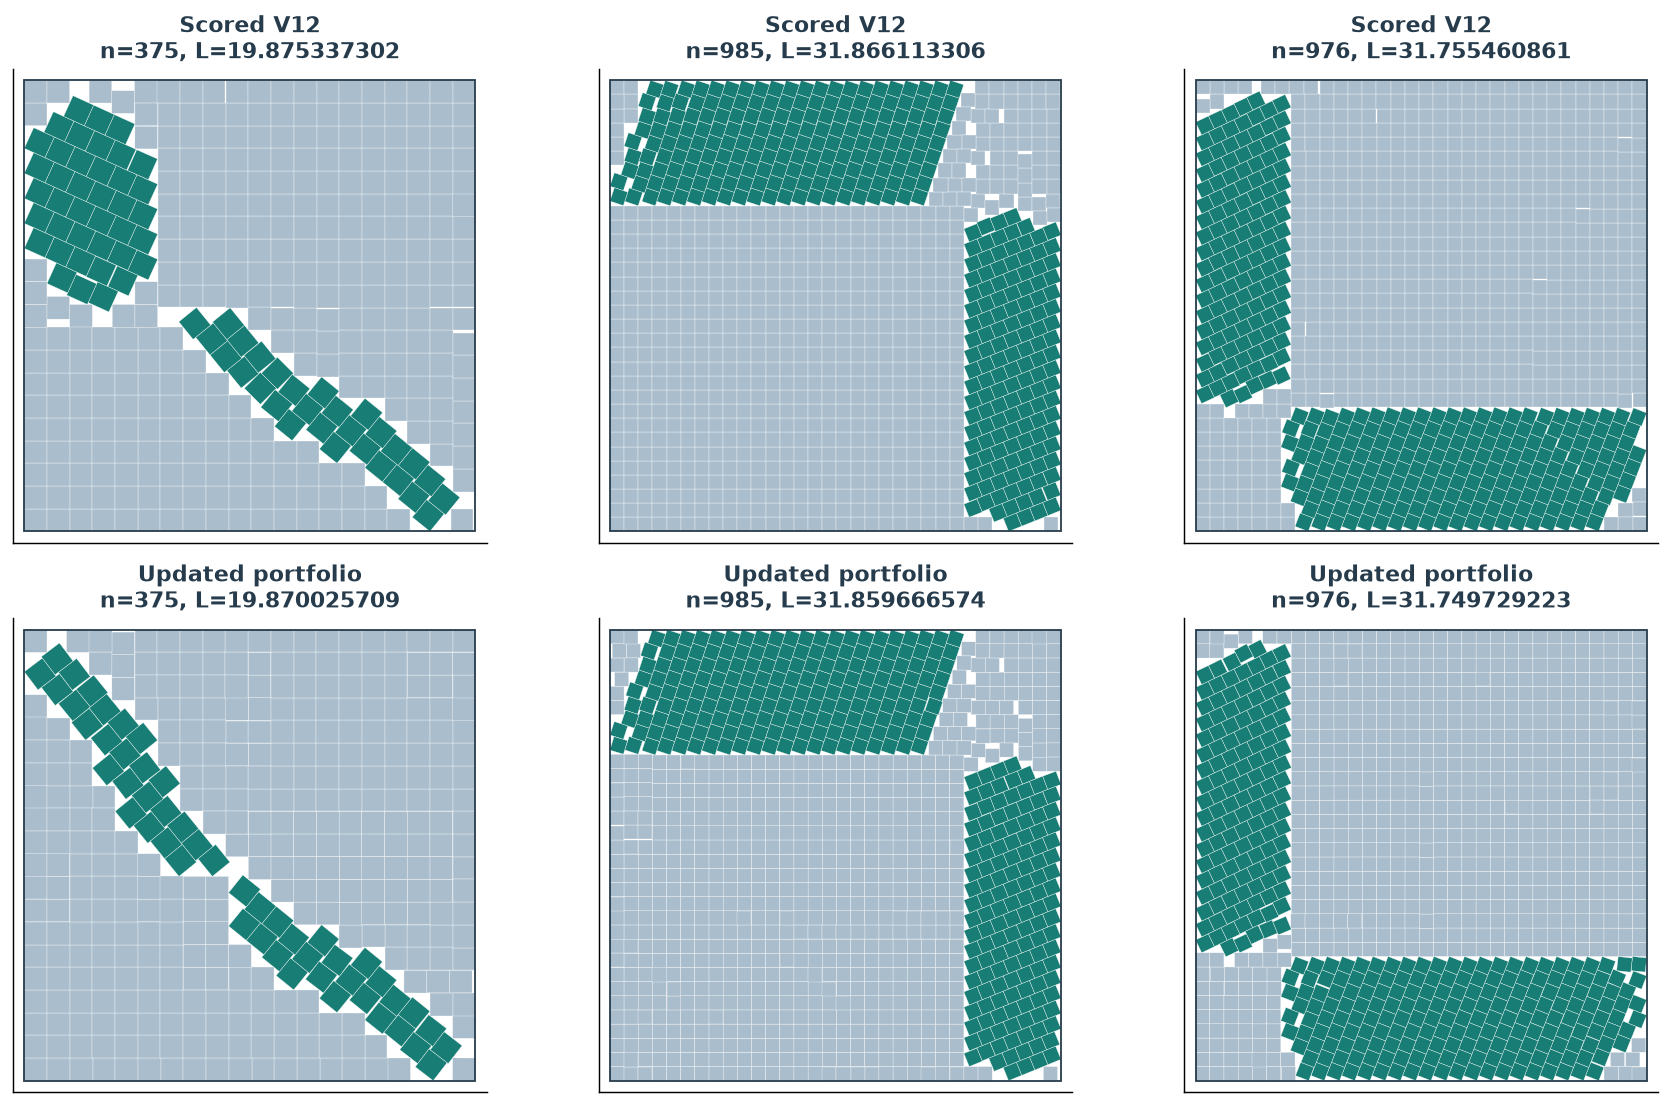

In [4]:
from matplotlib.patches import Polygon,Rectangle
from matplotlib.collections import PatchCollection
def vertices(p):
    offsets=np.array([[-.5,-.5],[.5,-.5],[.5,.5],[-.5,.5]])
    c,s=np.cos(p[:,2]),np.sin(p[:,2])
    return p[:,None,:2]+np.stack((c[:,None]*offsets[:,0]-s[:,None]*offsets[:,1],s[:,None]*offsets[:,0]+c[:,None]*offsets[:,1]),axis=2)
selected=changes.head(3).n.astype(int).tolist()
fig,axes=plt.subplots(2,len(selected),figsize=(13.8,8.6),squeeze=False)
for col,n in enumerate(selected):
    limit=side(before[n])
    for row,(label,bank) in enumerate([('Scored V12',before),('Updated portfolio',after)]):
        p=bank[n].copy();h=(abs(np.cos(p[:,2]))+abs(np.sin(p[:,2])))/2;p[:,:2]-=(p[:,:2]-h[:,None]).min(0)
        ax=axes[row,col];ax.add_collection(PatchCollection([Polygon(v) for v in vertices(p)],facecolors=np.where(abs(np.sin(2*p[:,2]))>.02,'#187e75','#a9bdcc'),edgecolors='white',linewidths=.18))
        ax.add_patch(Rectangle((0,0),side(p),side(p),fill=False,color='#263b4b',lw=1))
        ax.set(xlim=(-.025*limit,1.025*limit),ylim=(-.025*limit,1.025*limit),aspect='equal',xticks=[],yticks=[],title=f'{label}\nn={n}, L={side(p):.9f}')
fig.tight_layout();fig.savefig('contact_layouts.png',dpi=170,bbox_inches='tight');plt.show()

## 4. Feed new geometry back into the composition library

A useful local improvement can become a donor for many other puzzle sizes. The existing CUDA occupied-tip profile composer extracts rectangular crops under all eight symmetries and searches monotone staircase chains. Separating-line support profiles can certify a join even when both corner tips are occupied. After donor replacement, the library and DP are rebuilt; the measured incremental contribution appears in the stage table.

The donor bank and search budgets are finite. The method remains a heuristic over inherited and newly relaxed layouts. It does not establish global optimality or explain a private leaderboard solution. Earlier cold-start and shape-continuation pilots remain negative results, not credited improvements.

## 5. Readable source and optional additional CUDA search

The checked text archive below restores the complete sources, including CUDA C++, graph constraints, credited CPU helpers and unchanged official metric. The archived run1 source matches the first experiment checksum; the current runner also handles budgets shorter than CUDA initialization. Input coordinates are separately hash checked. The default replay imports no GPU libraries. Additional search requires NVIDIA CUDA and CuPy; the fixed budget can produce different candidates across environments. Admission retains the frozen result whenever a candidate fails or does not improve it.

In [5]:
import base64,zlib
payload=base64.b64decode('...')
assert hashlib.sha256(payload).hexdigest()=='c571936bfd46e1e18510ab63fd856fe1e3179088ba2e795fed78154b1746fc6d'
for name,source in json.loads(zlib.decompress(payload)).items():
    target=Path(name).resolve();assert target.is_relative_to(Path.cwd().resolve())
    target.parent.mkdir(parents=True,exist_ok=True);target.write_text(source,encoding='utf-8')
print('Readable CUDA C++ / Python sources and unchanged metric restored.')

Readable CUDA C++ / Python sources and unchanged metric restored.


In [6]:
Path('artifacts').mkdir(exist_ok=True)
Path('research').mkdir(exist_ok=True)
if RECOMPUTE_SEARCH:
    subprocess.run([sys.executable,'gpu_contact_restarts.py','--baseline',str(DATA/'contact_submission.csv'),'--seconds',str(SEARCH_SECONDS),'--batch',str(SEARCH_BATCH),'--tag','notebook_restarts'],check=True)
    subprocess.run([sys.executable,'research/contact-switch-refresh/assemble.py','--baseline',str((DATA/'contact_submission.csv').resolve()),'--tags','notebook_restarts','--tag','notebook_admitted'],check=True)
    shutil.copyfile('artifacts/notebook_admitted_submission.csv','submission.csv')
else:
    shutil.copyfile(DATA/'contact_submission.csv','submission.csv')
    assert hashlib.sha256(Path('submission.csv').read_bytes()).hexdigest()==manifest['contact_submission.csv']

## 6. Certify the serialized CSV

The unchanged official v17 checks the actual decimal strings, using interval arithmetic for uncertain contacts. A second complete check parses and reserializes them with ordinary pandas float64 conversion. Missing puzzle sizes use the permitted grid fallback. Local certification and the score attached to a submitted notebook version are recorded separately.

In [7]:
import mpmath
if not hasattr(mpmath.mpf(1),'man'):
    subprocess.run([sys.executable,'-m','pip','install','-q','mpmath==1.4.1'],check=True)
metric=Path('research/official_metric.py');metric.write_bytes(metric.read_text(encoding='utf-8').encode())
assert hashlib.sha256(metric.read_bytes()).hexdigest()=='312458227c78f56bd5e2eec3dc5fbb8787989422bbf72ce66c3c290048e89733'
subprocess.run([sys.executable,'research/validate_candidate.py','submission.csv','validation.json'],check=True,capture_output=True,text=True)
pd.read_csv('submission.csv').to_csv('float64_roundtrip.csv',index=False,float_format='%.17g')
subprocess.run([sys.executable,'research/validate_candidate.py','float64_roundtrip.csv','roundtrip_validation.json'],check=True,capture_output=True,text=True)
validated=json.loads(Path('validation.json').read_text());rt=json.loads(Path('roundtrip_validation.json').read_text())
assert not validated['rejected'] and not rt['rejected']
assert abs(validated['score']-rt['score'])<1e-10
assert validated['score']<=summary['score']+1e-10
if not RECOMPUTE_SEARCH:assert abs(validated['score']-22.383540245659237)<1e-10
display(HTML(f"<div style='padding:20px;border-left:5px solid #187e75;background:#eef6f4'><b style='font-size:25px'>Certified local score: {validated['score']:.12f}</b><br>{validated['puzzles']} accepted puzzles · {validated['rows']:,} rows · zero rejected<br>Float64 round trip: same score, zero rejected</div>"))
display(FileLink('submission.csv'))
Path('experiment_summary.json').write_text(json.dumps(summary,indent=2));changes.to_csv('improvements_over_v12.csv',index=False)

D:\Programming\Python AI ML\Kaggle\squares-in-squares\notebooks\cuda-contact-restarts\submission.csv

## Sources and limits

* [Kirill Tymchishin — Seam LP V5](https://www.kaggle.com/code/kirilltym/22-3856-cpu-cuda-mps-eda-seam-lp?scriptVersionId=361279753): eight imported numerical improvements, randomized graph reclosure, tangential seam-kick idea and credited CPU refinement helpers.
* [Janus — D4 Seam DP / Dual GPU L-BFGS](https://www.kaggle.com/code/jiwasawa/squares-in-squares-d4-seam-dp-dual-gpu-lbfgs): individually imported witnesses and a contraction-ladder experiment extending this notebook's earlier CUDA optimizer. His original discoverer credits remain applicable.
* [avazaku — Squarecraft II](https://www.kaggle.com/code/avazaku/squarecraft-ii-unjam-the-grid-22-408597-lb): binary contact switching and near-valid alternate axes.
* [Chris Deotte — Multi-Gadget Fault DP](https://www.kaggle.com/code/cdeotte/squares-in-squares-multi-gadget-fault-dp-22-48) and [L-Cut & GPU Squeeze](https://www.kaggle.com/code/cdeotte/squares-in-squares-l-cut-gpu-squeeze-22-41): fault composition and rectangular donor construction.
* [Alex Chilton — Basin Hopping](https://www.kaggle.com/code/alexchilton/fault-line-dp-basin-hopping-lb-22-3945), [Dariush Afshar — Certified Packings](https://www.kaggle.com/datasets/dariushafshar/squares-in-squares-certified-packings/versions/8), Kozykappa, Prvsiyan, SeshuRaju and Malyshev Danil: inherited public portfolio and source lineage, retained in the checked notices.
* [Francisco Couzo and original discoverers](https://github.com/franciscouzo/square-packing), [Evan Daniel](https://github.com/evand/square-packing), [Joshua Levy and contributors](https://github.com/jlevy/squares), Darius Muglich (CC BY 4.0) and the per-witness authors retain their credits and licenses. No inherited mathematical discovery is attributed to this implementation.
* [Official metric v17](https://www.kaggle.com/code/metric/squares-in-squares?scriptVersionId=360167936), unchanged, Apache 2.0. Full notices: `contact_SOURCE_NOTICES.md`, `contact_kirill_notices.md` and prior Layout Atlas records.

Finite restarts, bounded contact choices and conservative composition profiles do not establish an optimum. Default replay is deterministic; additional time-limited search may differ. GPU proposals use float64 here, but floating-point feasibility alone is never a submission certificate.

## 7. Professional experiment analytics and reproducibility manifest

This section executes only after the original validation succeeds. It exports a structured summary, comparison charts and a machine-readable environment manifest. Numerical claims remain tied to the validated original output.

In [ ]:
import platform, datetime, importlib.metadata as metadata
from pathlib import Path
import json, hashlib
report_dir = Path('artifacts/professional_reports')
report_dir.mkdir(parents=True,exist_ok=True)
comparison = pd.DataFrame([
    {'stage':'V12','score':sum(side(p)**2/n for n,p in before.items())},
    {'stage':'Public baseline','score':sum(side(p)**2/n for n,p in public.items())},
    {'stage':'Validated submission','score':float(validated['score'])},
])
comparison['delta_vs_v12'] = comparison['score'] - comparison.loc[0,'score']
display(comparison.style.format({'score':'{:.12f}','delta_vs_v12':'{:+.12f}'}))
ax = comparison.plot.bar(x='stage',y='score',legend=False,figsize=(9,4),title='Packing objective comparison')
ax.set_ylabel('Objective (lower is better)')
ax.figure.tight_layout()
ax.figure.savefig(report_dir/'objective_comparison.png',dpi=160)
plt.show()
comparison.to_csv(report_dir/'objective_comparison.csv',index=False)
packages={name:metadata.version(name) for name in ['numpy','pandas','matplotlib','mpmath']}
run_manifest={'generated_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'python':platform.python_version(),'platform':platform.platform(),
 'packages':packages,'search_recomputed':bool(RECOMPUTE_SEARCH),
 'input_manifest_sha256':hashlib.sha256((DATA/'contact_manifest.json').read_bytes()).hexdigest(),
 'submission_sha256':hashlib.sha256(Path('submission.csv').read_bytes()).hexdigest(),
 'validation':validated,'roundtrip_validation':rt,
 'objective_comparison':comparison.to_dict(orient='records')}
(report_dir/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2,default=str))
print('Saved:',report_dir.resolve())